https://docs.langchain.com/oss/python/langchain/middleware/overview

在create_agent()的底层运行机制中，有几个重要的组件，分别是：
- 模型(Model)：Agent的大脑，负责理解任务和决策推理。
- 工具(Tools)：Agent的手脚，执行模型自己做不到的外部操作。
- 系统提示词(System Prompt)：Agent的角色，告诉模型该怎么想、参考什么上下文。
- 中间件(Middleware)：Agent的中枢，在执行流程的关键节点进行拦截、控制和增强。

声明如下：

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware, HumanInTheLoopMiddleware

agent = create_agent(
    model="gpt-5.5",
    tools=[...],
    middleware=[
        SummarizationMiddleware(...),
        HumanInTheLoopMiddleware(...)
    ],
)

## 1、什么是中间件
Middleware(中间件)，简单说就是Agent执行过程中的钩子函数，是LangChain 1.x的王牌工程化能力。

钩子是框架或系统在某些关键执行点暴露的扩展接口。开发者可以“挂上”自己的逻辑，在那些点上插入、修改或替换行为，而无需改变主流程代码。就像在流水线上某个环节设置了一个“检查点”或“插入器”。

借助中间件，开发者可以高度定制和控制Agent运行的每一个环节，是处理Agent生命周期的标准方式。

没有中间件的Agent架构：

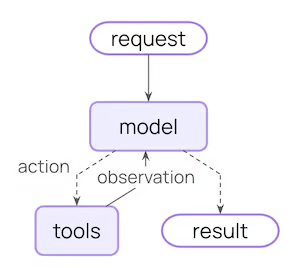

添加中间件之后的Agent架构变为：

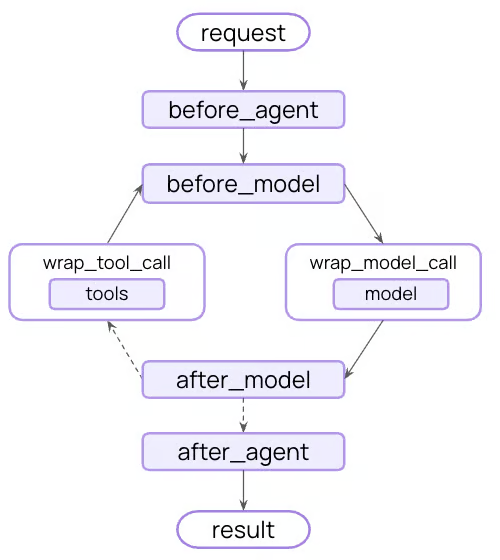

在 LangChain 的 Agent 执行循环中，比如 “模型调用前”、“模型调用后”、“工具调用前后” 设置一些钩子（hooks），让你在不改 Agent 主体逻辑的情况下实现策略与治理。

## 2、为什么需要中间件
如果没有中间件，Agent 的执行流程通常比较直接：
```
用户输入 -> 拼接提示词/消息 -> 调用模型 -> 如有需要调用工具 -> 返回结果
```

这种方式对于简单场景已经足够，但是真实项目往往会遇到很多额外需求，比如：
- 想根据问题复杂度动态切换模型。
- 想限制某些用户只能调用部分工具。
- 想在工具报错时自动重试或返回兜底结果。
- 想在模型调用前插入额外的系统提示。
- 想记录每一步的执行日志，方便排查问题。
- 想在敏感信息出现时阻断执行。
- 想在正式执行工具前增加人工审批。

这些需求有一个共同点：它们不是Agent的核心业务逻辑，但又会影响Agent的执行过程。如果把这些逻辑全部写进主流程，会带来几个问题：
- 主流程会迅速变乱：Agent本身只关心“理解用户需求，决定是否调用工具，生成结果”，但一旦把日志、鉴权、重试、风控、审计都塞进去，主逻辑会变得臃肿。
- 很多逻辑是横切需求，难以复用：例如日志、重试、风控、权限控制，通常不是某一个Agent独有的，而是多个Agent都需要。如果直接写死在每个Agent里，会产生大量重复代码。
- 流程控制粒度不够细：有些逻辑必须发生在模型调用前，有些要发生在工具调用后，如果没有统一的执行拦截点，开发者只能手动改主流程，既麻烦又容易出错。
- 后期维护成本高：当你需要增加一个新规则，例如“所有外部工具调用前都先做审计”，如果系统没有中间件机制，往往需要修改很多处代码。

总结：中间件的价值就在于把这些与业务无关、但与执行过程强相关的横切逻辑，从 Agent 主流程中分离出来。让Agent 主体代码 聚焦业务 ，而借助中间件，实现“ 拦截流程、修改流程、增强流程 ”

简言之，LangChain 1.x 的中间件能实现如下功能：
- ✅ 日志与分析 - 追踪行为、调试、性能监控
- ✅ 转换 - 修改提示词、工具选择、输出格式
- ✅ 容错 - 重试、降级、早期终止
- ✅ 安* - 限流、守护规则、PII 检测

## 3、中间件的分类

- 自定义中间件：允许开发者自定义，从而实现更加灵活的Agent行为管理
- 内置中间件：LangChain实现并提供的
    - 模型供应商定制的中间件 ：依赖于特定模型服务的实现
    - 和模型供应商无关的中间件。

内置的与模型无关的中间件如下：

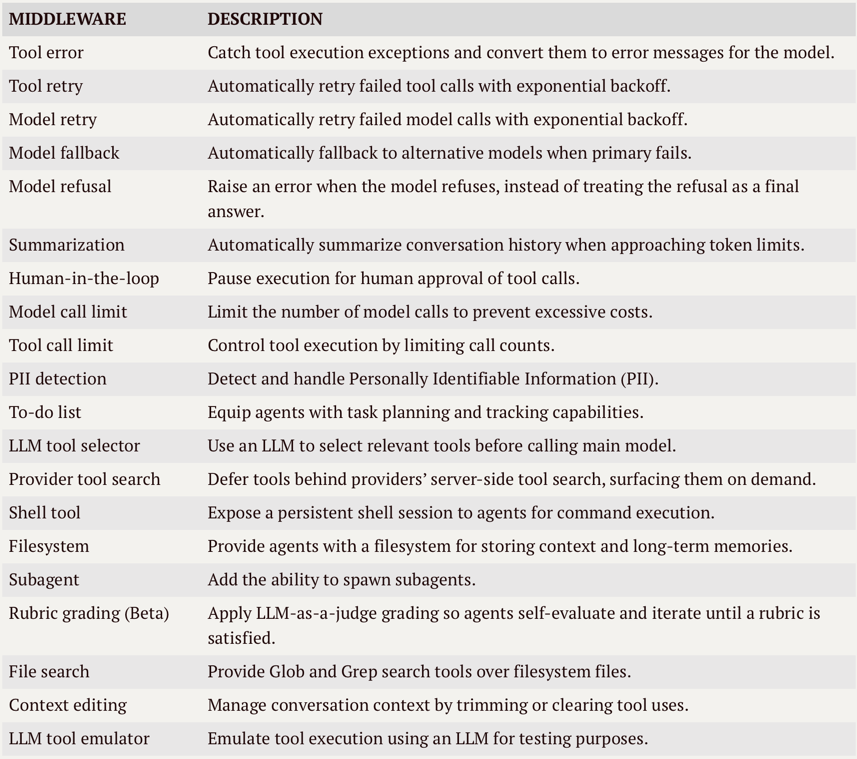

## 4、内置中间件分类
### 4.1 类型1:成本与资源控制类

核心目标：**控成本、控配额、避免无限调用**。这类中间件主要解决**Agent太贵、太能跑、停不下来**的问题。

包含：
- Model call limit：限制模型调用次数，防止一次任务反复请求LLM，导致费用失控。
- Tool call limit：限制工具调用次数，避免Agent无限试错，死循环调用工具。
- Summarization：在上下文快满时自动总结历史，减少token消耗。
- Context editing：裁剪上下文、清理工具调用痕迹，本质上也是为了节省上下文成本。

业务场景理解：适合生产环境的成本治理、配额治理、长会话优化、SaaS 产品控费。

### 4.2 类型2:稳定性与容错性保障

核心目标：**保证服务不中断、失败后尽量自动恢复**。这类中间件主要解决**调用失败怎么办、模型挂了怎么办、工具超时怎么办**。

包含：
- Model fallback：主模型失败时切换备用模型。
- Model retry：模型调用失败后自动重试。
- Tool retry：工具调用失败后自动重试。
- Tool error：捕获工具执行异常并转换为错误消息返回给模型，避免异常直接中断Agent流程。

业务场景理解：适合线上生产系统，尤其是多模型、多工具依赖的 Agent。本质上是在做 高可用、容灾、鲁棒性建设。

### 4.3 类型3:安全与合规风控类

核心目标：**让Agent可控、可审、合规**。这类中间件主要解决**Agent乱执行、泄露敏感信息、做危险操作**等问题。

包含：
- Human-in-the-loop：在关键工具调用前暂停，等人工审批。
- PII detection：检测和处理个人敏感信息。
- Model call limit / Tool call limit：某种意义上也可归到风控，因为它能防止异常调用。
- Model refusal：当模型拒绝响应时主动抛出错误，而不是把拒绝当成最终答案继续执行。

业务场景理解：适合企业内部系统、客服系统、审批流、数据查询类 Agent。尤其是涉及：发邮件、调数据库、调财务/人事系统、导出敏感信息、执行外部动作等

### 4.4 类型4:决策增强与智能编排类

核心目标：**提升Agent的决策质量和任务拆解能力**。这类中间件主要解决**Agent不够聪明、不会规划、不会先筛工具**的问题。

包含：
- To-do list：给Agent增加任务规划、分步骤执行和状态跟踪能力。
- LLM tool selector：当工具太多时，用子模型筛选最相关的几个工具交给主模型。
- Subagent：允许生成子Agent，把复杂任务拆给不同角色处理。
- Provider tool search：将工具延迟到供应商服务端按需搜索和浮现，避免一次性向模型暴露过多工具。
- Rubric grading (Beta)：使用 LLM-as-a-judge 按评分标准让 Agent 自评并迭代，直到满足 rubric 要求。

业务场景理解：适合复杂任务流，比如：研究型 Agent、多步骤分析、报告生成、多角色协作、长链路任务编排等。类本质上是在增强 Agent的“脑子”与“组织能力”。

### 4.5 类型5:执行能力扩展类

核心目标：给 Agent 更多“手脚”。这类中间件主要解决“ Agent只能聊天，不能真正操作环境 ”的问题。

包含：
- Shell tool：给 Agent 持久 shell，会执行命令
- File search：给 Agent 文件搜索能力，能做 Glob/Grep
- Filesystem：给 Agent 文件系统读写与长期存储能力

业务场景理解：适合工程 Agent、代码 Agent、本地自动化 Agent、运维 Agent。本质上是把 Agent 从“纯推理”扩展成“能操作环境的执行体”。

### 4.6 类型6:开发调试与测试辅助类

核心目标：方便开发、测试、验证 Agent 行为，这类中间件主要不是直接服务业务，而是服务于 研发和调试阶段 。

包含：
- LLM tool emulator：用 LLM 模拟工具执行，便于测试（最典型）
- Summarization：有时也可辅助调试长会话表现
- Context editing：可用于测试上下文裁剪效果
- Human-in-the-loop：也常用于调试高风险步骤

业务场景理解：适合开发阶段快速验证流程、做 mock、减少真实工具依赖。